# DataPact - A6 Part 1: Hugging Face model lab (3B+ models)

**INFO 490 MG, Team 15. Larger-model runs: Connor Slattery.**

The main benchmark (`ai_prototype.ipynb`, Hriday Agarwal) tested 15 models, all under 2B
parameters, because the free Colab session ran out of memory on anything bigger. This notebook
fills in the missing sizes on a local GPU with 24 GB of memory:

| Category | Model | Parameters |
|---|---|---|
| Medium (3B - under 7B) | Qwen/Qwen2.5-3B-Instruct | about 3.1B |
| Medium (3B - under 7B) | tiiuae/Falcon3-3B-Instruct | about 3.2B |
| Medium (3B - under 7B) | microsoft/Phi-3.5-mini-instruct | about 3.8B |
| Large (7B+) | Qwen/Qwen2.5-7B-Instruct | about 7.6B |

**Same test, same scoring.** The 8 fixed inputs, the 12-example pool, the prompt, the model
loading, greedy generation (`do_sample=False`, 160 new tokens) and the scoring are copied
word for word from the main benchmark. Only the model list and the results folder change.
`ai_prototype.ipynb` and `results_light/` are not touched; this notebook only reads
`results_light/` to compare against it.

**What it does**

1. Installs libraries and downloads all the model weights (top cells).
2. **Matrix test:** the 4 models on the 8 inputs, zero-shot, exactly like the main benchmark.
3. **Route A:** all 4 models with zero-, one-, few- and many-shot prompts. With only 4 models,
   every one is tested instead of a top 3.
4. **Size comparison:** these results next to the 15 light models, to answer the Part 3
   question of whether a bigger model is worth it.

Results are saved to `results_3b_plus/` after every model, so a crash can be resumed by
running all cells again.

## 1. Install libraries

* `transformers` downloads a model by name and runs it. `accelerate` places it on the GPU.
* **PyTorch is installed separately**, because the right build depends on the GPU. This run
  used AMD's ROCm build of PyTorch for Windows (an AMD Radeon GPU still shows up to PyTorch as
  `cuda`). On Colab or an NVIDIA machine the normal PyTorch already works.

In [1]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
packages = ["transformers==5.20.1", "accelerate==1.15.0", "pandas", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: False


## 2. Settings and the 4 models

Parameter counts are read from each model's `safetensors` metadata on Hugging Face, the same
way the main benchmark got its numbers. The numbers in the list are only used if that lookup
fails.

Set `SMOKE_TEST = True` (or the environment variable `SMOKE_TEST=1`) to try the smallest model
on 2 inputs first. That checks the GPU setup in a few minutes before the full run.

In [2]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"  # set True for a quick check

MODELS = [
    # (category, Hugging Face id, parameters in billions if the lookup fails)
    ("Medium (3B-7B)", "Qwen/Qwen2.5-3B-Instruct", 3.09),
    ("Medium (3B-7B)", "tiiuae/Falcon3-3B-Instruct", 3.23),
    ("Medium (3B-7B)", "microsoft/Phi-3.5-mini-instruct", 3.82),
    ("Large (7B+)", "Qwen/Qwen2.5-7B-Instruct", 7.62),
]
CATEGORY_ORDER = ["Medium (3B-7B)", "Large (7B+)"]
MAX_NEW_TOKENS = 160  # same as the main benchmark
RESULTS = "results_3b_plus"

if SMOKE_TEST:
    MODELS = MODELS[:1]
    RESULTS = "results_3b_plus_smoke"  # keeps test rows out of the real results

import torch
from huggingface_hub import get_safetensors_metadata


def real_params_b(model_id, fallback):
    try:
        counts = get_safetensors_metadata(model_id).parameter_count
        return round(sum(counts.values()) / 1e9, 2)
    except Exception:
        return fallback


MODELS = [(cat, model_id, real_params_b(model_id, b)) for cat, model_id, b in MODELS]

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Device:", DEVICE, "| smoke test:", SMOKE_TEST, "| models to test:", len(MODELS))
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    print("GPU:", props.name, f"({props.total_memory / 1e9:.0f} GB)")
for cat, model_id, b in MODELS:
    print(f"  {cat:15} {model_id:35} {b}B  ~{b * 2:.1f} GB in 16-bit")

C:\Users\Connor\Documents\UIUC\Fall 2026\INFO 490\llm-venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Parse safetensors files:   0%|          | 0/2 [00:00<?, ?it/s]

Parse safetensors files:  50%|█████     | 1/2 [00:00<00:00,  3.29it/s]

Parse safetensors files: 100%|██████████| 2/2 [00:00<00:00,  5.55it/s]

C:\Users\Connor\Documents\UIUC\Fall 2026\INFO 490\llm-venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Connor\.cache\huggingface\hub\models--tiiuae--Falcon3-3B-Instruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


...

Parse safetensors files:  25%|██▌       | 1/4 [00:00<00:00,  7.19it/s]

Parse safetensors files:  50%|█████     | 2/4 [00:00<00:00,  7.49it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:00<00:00, 11.22it/s]

Parse safetensors files: 100%|██████████| 4/4 [00:00<00:00, 10.15it/s]

Device: cuda | smoke test: False | models to test: 4
GPU: AMD Radeon RX 7900 XTX (26 GB)
  Medium (3B-7B)  Qwen/Qwen2.5-3B-Instruct            3.09B  ~6.2 GB in 16-bit
  Medium (3B-7B)  tiiuae/Falcon3-3B-Instruct          3.23B  ~6.5 GB in 16-bit
  Medium (3B-7B)  microsoft/Phi-3.5-mini-instruct     3.82B  ~7.6 GB in 16-bit
  Large (7B+)     Qwen/Qwen2.5-7B-Instruct            7.62B  ~15.2 GB in 16-bit


## 3. Downloading the model weights

`snapshot_download` saves the weights (`.safetensors` files) to the Hugging Face cache, which is
outside the repository, so they can never be committed. All 4 models together are about 37 GB.

Unlike the Colab run, the weights are **kept** after each test, because every model is used
again in Route A and downloading them twice would double the time. Set `DELETE_AFTER_TEST =
True` to free the disk space at the end instead. A stalled download (no data for 60 seconds)
is retried up to 3 times and resumes where it stopped.

In [3]:
import shutil
import time

# Give up on a connection that sends nothing for 60 s (must be set before the import below).
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
from huggingface_hub import scan_cache_dir, snapshot_download

WEIGHT_FILES = ["*.json", "*.safetensors", "*.model", "*.txt", "*.py", "*.tiktoken"]
DELETE_AFTER_TEST = False


def free_gb():
    return shutil.disk_usage(os.path.expanduser("~")).free / 1e9


def size_on_disk_gb(model_id):
    try:
        repos = scan_cache_dir().repos
    except Exception:  # no cache folder yet
        return 0.0
    for repo in repos:
        if repo.repo_id == model_id:
            return repo.size_on_disk / 1e9
    return 0.0


def download(model_id, attempts=3):
    for attempt in range(1, attempts + 1):
        try:
            return snapshot_download(model_id, allow_patterns=WEIGHT_FILES)
        except Exception as error:  # a dropped connection resumes where it stopped
            print(f"   download attempt {attempt} failed: {type(error).__name__}")
            if attempt == attempts:
                raise
            time.sleep(10)


def delete_from_cache(model_id):
    for repo in scan_cache_dir().repos:
        if repo.repo_id == model_id:
            hashes = [rev.commit_hash for rev in repo.revisions]
            scan_cache_dir().delete_revisions(*hashes).execute()


print(f"Free disk: {free_gb():.1f} GB (about 37 GB needed for all 4 models)")
for _, model_id, _ in MODELS:
    start = time.time()
    print(f"Downloading {model_id} ...", flush=True)
    download(model_id)
    print(f"   {size_on_disk_gb(model_id):.1f} GB on disk, {time.time() - start:.0f}s")

Free disk: 71.3 GB (about 37 GB needed for all 4 models)


Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 2999.98it/s]

   6.2 GB on disk, 0s


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

...

Fetching 11 files:  73%|███████▎  | 8/11 [01:41<00:42, 14.31s/it]

Fetching 11 files:  82%|████████▏ | 9/11 [01:52<00:27, 13.79s/it]

Fetching 11 files:  91%|█████████ | 10/11 [01:53<00:11, 11.26s/it]

Fetching 11 files: 100%|██████████| 11/11 [01:54<00:00, 10.43s/it]

   15.2 GB on disk, 115s


## 4. The fixed inputs (copied from the main benchmark)

The same 8 failed checks with the right answers (4 `DATA_ISSUE`, 4 `CONTRACT_UPDATED`, so
always giving one answer scores 50%), and the same 12-example pool for Route A.

In [4]:
TEST_CASES = [
    dict(id="T1", dataset="Monthly Enrollment Export", column="credit_hours",
         rule='RANGE {"min": 0, "max": 24}', failed="47 of 4,812 rows",
         samples="[31, 99, -2]", label="DATA_ISSUE"),
    dict(id="T2", dataset="Monthly Enrollment Export", column="status",
         rule='ALLOWED_VALUES ["ENROLLED", "DROPPED", "WITHDRAWN"]', failed="4 of 4,812 rows",
         samples='["AUDIT", "AUDIT", "AUDIT", "AUDIT"]', label="CONTRACT_UPDATED"),
    dict(id="T3", dataset="Monthly Enrollment Export", column="student_id",
         rule='REGEX "^[0-9]{8}$"', failed="12 of 4,812 rows",
         samples='["1234567", "12345678A", "ABC00012"]', label="DATA_ISSUE"),
    dict(id="T4", dataset="Sensor Readings - Lab 3", column="temperature_c",
         rule='RANGE {"min": -10, "max": 50}', failed="6 of 8,640 rows",
         samples="[-9999, -9999, -9999]", label="DATA_ISSUE"),
    dict(id="T5", dataset="Library Circulation Log", column="branch",
         rule='ALLOWED_VALUES ["MAIN", "GRAINGER", "UNDERGRAD"]', failed="310 of 9,800 rows",
         samples='["FUNK_ACES", "FUNK_ACES", "FUNK_ACES"]', label="CONTRACT_UPDATED"),
    dict(id="T6", dataset="Payroll Deductions Export", column="deduction_code",
         rule='ALLOWED_VALUES ["FED", "STATE", "MEDICARE", "SOCSEC"]', failed="512 of 3,402 rows",
         samples='["HSA", "HSA", "HSA"]', label="CONTRACT_UPDATED"),
    dict(id="T7", dataset="Course Catalog Snapshot", column="term_code",
         rule='ALLOWED_VALUES ["FA", "SP", "SU"]', failed="85 of 2,100 rows",
         samples='["WI", "WI", "WI"]', label="CONTRACT_UPDATED"),
    dict(id="T8", dataset="Facilities Work Orders", column="order_id",
         rule="UNIQUE", failed="14 of 2,210 rows",
         samples='["WO-10233", "WO-10233", "WO-10871", "WO-10871"]', label="DATA_ISSUE"),
]

EXAMPLE_POOL = [
    (dict(dataset="Weekly Sales Extract", column="quantity", rule='RANGE {"min": 1, "max": 1000}',
          failed="9 of 13,120 rows", samples="[0, -3, 0]"),
     dict(explanation="Some sales rows have a quantity of zero or below, which cannot happen for a real sale.",
          likely_cause="DATA_ISSUE", suggested_action="Ask the sales team to correct the quantities in those rows.")),
    (dict(dataset="Monthly Enrollment Export", column="college", rule='ALLOWED_VALUES ["LAS", "ENG", "BUS", "ACES"]',
          failed="220 of 4,812 rows", samples='["CDS", "CDS", "CDS"]'),
     dict(explanation="Many students are listed under CDS, which looks like a newly created college rather than a typo.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm CDS is a real college and add it to the allowed values.")),
    (dict(dataset="Sensor Readings - Lab 3", column="humidity_pct", rule='TYPE_MATCH {"type": "number"}',
          failed="4 of 8,640 rows", samples='["N/A", "err", "N/A"]'),
     dict(explanation="A few humidity readings are text error markers instead of numbers.",
          likely_cause="DATA_ISSUE", suggested_action="Check the sensor logger and re-export the affected readings.")),
    (dict(dataset="Facilities Work Orders", column="priority", rule='ALLOWED_VALUES ["LOW", "MEDIUM", "HIGH"]',
          failed="140 of 2,210 rows", samples='["URGENT", "URGENT", "URGENT"]'),
     dict(explanation="Work orders now use an URGENT priority that the contract does not list yet.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm URGENT is an official priority and add it to the contract.")),
    (dict(dataset="Library Circulation Log", column="checkout_date", rule="NOT_NULL",
          failed="2 of 9,800 rows", samples="[null, null]"),
     dict(explanation="Two checkouts are missing their date, which every checkout must have.",
          likely_cause="DATA_ISSUE", suggested_action="Find the missing dates in the circulation system and fix the export.")),
    (dict(dataset="Course Catalog Snapshot", column="credit_hours", rule='RANGE {"min": 1, "max": 5}',
          failed="18 of 2,100 rows", samples="[6, 6, 6]"),
     dict(explanation="Several courses are worth 6 credits, consistent with a newly approved capstone format.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm the 6-credit courses and raise the maximum to 6.")),
    (dict(dataset="Payroll Deductions Export", column="employee_id", rule="UNIQUE",
          failed="5 of 3,402 rows", samples='["E1001", "E1001", "E2044"]'),
     dict(explanation="Some employee IDs appear more than once, so the same people were exported twice.",
          likely_cause="DATA_ISSUE", suggested_action="Remove the duplicate rows and check why the export repeated them.")),
    (dict(dataset="Weekly Sales Extract", column="region", rule='ALLOWED_VALUES ["NORTH", "SOUTH", "EAST", "WEST"]',
          failed="1,500 of 13,120 rows", samples='["ONLINE", "ONLINE", "ONLINE"]'),
     dict(explanation="A large, consistent block of sales is tagged ONLINE, which looks like a new sales channel.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm ONLINE is a real region and add it to the contract.")),
    (dict(dataset="Monthly Enrollment Export", column="email", rule='REGEX "^[^@]+@illinois\\.edu$"',
          failed="7 of 4,812 rows", samples='["jdoe@illinois", "@illinois.edu"]'),
     dict(explanation="A few email addresses are incomplete and would not work.",
          likely_cause="DATA_ISSUE", suggested_action="Correct the malformed addresses at the source.")),
    (dict(dataset="Sensor Readings - Lab 3", column="sensor_id", rule='ALLOWED_VALUES ["S1", "S2", "S3", "S4", "S5", "S6", "S7", "S8"]',
          failed="720 of 8,640 rows", samples='["S9", "S9", "S9"]'),
     dict(explanation="Readings arrive steadily from a sensor S9, which suggests a new sensor was installed.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm sensor S9 exists and add it to the allowed list.")),
    (dict(dataset="Facilities Work Orders", column="cost_usd", rule='TYPE_MATCH {"type": "number"}',
          failed="3 of 2,210 rows", samples='["$1,200", "TBD"]'),
     dict(explanation="A few costs were typed as text with symbols or placeholders instead of numbers.",
          likely_cause="DATA_ISSUE", suggested_action="Re-enter those costs as plain numbers.")),
    (dict(dataset="Library Circulation Log", column="item_type", rule='ALLOWED_VALUES ["BOOK", "DVD", "JOURNAL"]',
          failed="410 of 9,800 rows", samples='["LAPTOP", "LAPTOP", "LAPTOP"]'),
     dict(explanation="Many loans are for laptops, which matches a new lending service the contract predates.",
          likely_cause="CONTRACT_UPDATED", suggested_action="Confirm laptop lending and add LAPTOP to the allowed values.")),
]

SHOT_COUNTS = {"zero-shot": 0, "one-shot": 1, "few-shot": 3, "many-shot": 12}

if SMOKE_TEST:
    TEST_CASES = [TEST_CASES[0], TEST_CASES[1]]

print(len(TEST_CASES), "test cases,", len(EXAMPLE_POOL), "pool examples")

8 test cases, 12 pool examples


## 5. Building the prompt (copied from the main benchmark)

In [5]:
import json

INSTRUCTIONS = (
    "You review failed data-quality checks for DataPact. A failure means either the incoming "
    "data is wrong (DATA_ISSUE) or the data is legitimate and the rule is out of date "
    "(CONTRACT_UPDATED).\n"
    "Reply with ONLY a JSON object, no other text, with exactly these keys:\n"
    '  "explanation": one plain-English sentence,\n'
    '  "likely_cause": "DATA_ISSUE" or "CONTRACT_UPDATED",\n'
    '  "suggested_action": one short sentence.'
)


def describe(case):
    return (
        f"Dataset: {case['dataset']}\nColumn: {case['column']}\nRule: {case['rule']}\n"
        f"Rows failed: {case['failed']}\nSample values: {case['samples']}"
    )


def build_messages(case, n_shots):
    messages = []
    for i, (example, answer) in enumerate(EXAMPLE_POOL[:n_shots]):
        text = describe(example)
        if i == 0:
            text = INSTRUCTIONS + "\n\n" + text
        messages.append({"role": "user", "content": text})
        messages.append({"role": "assistant", "content": json.dumps(answer)})
    question = describe(case)
    if n_shots == 0:
        question = INSTRUCTIONS + "\n\n" + question
    messages.append({"role": "user", "content": question})
    return messages


print("Zero-shot prompt for T1:\n")
print(build_messages(TEST_CASES[0], 0)[-1]["content"])

Zero-shot prompt for T1:

You review failed data-quality checks for DataPact. A failure means either the incoming data is wrong (DATA_ISSUE) or the data is legitimate and the rule is out of date (CONTRACT_UPDATED).
Reply with ONLY a JSON object, no other text, with exactly these keys:
  "explanation": one plain-English sentence,
  "likely_cause": "DATA_ISSUE" or "CONTRACT_UPDATED",
  "suggested_action": one short sentence.

Dataset: Monthly Enrollment Export
Column: credit_hours
Rule: RANGE {"min": 0, "max": 24}
Rows failed: 47 of 4,812 rows
Sample values: [31, 99, -2]


## 6. Loading, running and scoring a model (copied from the main benchmark)

16-bit weights, greedy decoding, the first `{...}` parsed as JSON, then checked for the three
keys and an allowed `likely_cause`. Peak memory is measured on the GPU. The 7B model needs
about 15 GB, which fits in 24 GB but not in Colab's T4.

In [6]:
import gc
import re
import time

from transformers import AutoModelForCausalLM, AutoTokenizer

REQUIRED_KEYS = {"explanation", "likely_cause", "suggested_action"}
CAUSES = {"DATA_ISSUE", "CONTRACT_UPDATED"}


def load(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    kwargs = {"dtype": torch.float16 if DEVICE != "cpu" else torch.float32}
    if DEVICE == "cuda":
        kwargs["device_map"] = "cuda"
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if DEVICE != "cuda":
        model.to(DEVICE)
    model.eval()
    return tokenizer, model


def unload(model):
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def generate(tokenizer, model, messages):
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to(model.device)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(
            **inputs, max_new_tokens=MAX_NEW_TOKENS, do_sample=False,
            pad_token_id=tokenizer.pad_token_id)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    seconds = time.perf_counter() - start
    new_tokens = output[0][inputs["input_ids"].shape[1]:]
    text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
    return text, seconds, len(new_tokens), inputs["input_ids"].shape[1]


def score(text, label):
    result = {"valid_json": False, "schema_ok": False, "correct": False, "predicted": None}
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        return result
    try:
        data = json.loads(match.group(0))
    except json.JSONDecodeError:
        return result
    if not isinstance(data, dict):
        return result
    result["valid_json"] = True
    cause = str(data.get("likely_cause", "")).strip().upper()
    result["predicted"] = cause or None
    result["schema_ok"] = REQUIRED_KEYS.issubset(data) and cause in CAUSES
    result["correct"] = cause == label
    return result


def run(model_id, category, n_shots, method):
    tokenizer, model = load(model_id)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    rows = []
    for case in TEST_CASES:
        text, seconds, n_new, n_prompt = generate(tokenizer, model, build_messages(case, n_shots))
        rows.append({
            "model": model_id.split("/")[-1], "model_id": model_id, "category": category,
            "method": method, "case": case["id"], "label": case["label"],
            "prompt_tokens": n_prompt, "new_tokens": n_new, "seconds": round(seconds, 2),
            "tokens_per_s": round(n_new / seconds, 1) if seconds else None,
            "output": text, **score(text, case["label"]),
        })
    peak_gb = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else None
    for row in rows:
        row["peak_mem_gb"] = round(peak_gb, 2) if peak_gb else None
    unload(model)
    return rows

## 7. Matrix test: 4 models x 8 inputs, zero-shot

Same as the main benchmark's matrix test. The CSV is rewritten after every model, so running
all cells again skips the models that already finished.

In [7]:
import pandas as pd

os.makedirs(RESULTS, exist_ok=True)
SIZE = {model_id: params for _, model_id, params in MODELS}
MATRIX_CSV = f"{RESULTS}/matrix_results.csv"


def load_saved(path):
    if os.path.exists(path):
        return pd.read_csv(path).to_dict("records")
    return []


matrix_rows = load_saved(MATRIX_CSV)
done = {row["model_id"] for row in matrix_rows}
if done:
    print("Resuming: already finished", len(done), "models")

for category, model_id, params in MODELS:
    if model_id in done:
        continue
    print(f"[{category}] {model_id} ...", flush=True)
    try:
        download(model_id)
        matrix_rows += run(model_id, category, 0, "zero-shot")
    except Exception as error:  # one broken model should not stop the others
        print("   failed:", type(error).__name__, error)
    pd.DataFrame(matrix_rows).to_csv(MATRIX_CSV, index=False)

matrix = pd.DataFrame(matrix_rows)
matrix = matrix[matrix["model_id"].isin(SIZE)]
matrix["params_b"] = matrix["model_id"].map(SIZE)
matrix.to_csv(MATRIX_CSV, index=False)
print("Saved", MATRIX_CSV, "with", len(matrix), "rows from", matrix["model_id"].nunique(), "models")

[Medium (3B-7B)] Qwen/Qwen2.5-3B-Instruct ...


Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 2998.55it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Loading weights:   5%|▌         | 23/434 [00:00<00:02, 178.14it/s]

...

Loading weights:  91%|█████████ | 308/339 [00:09<00:01, 23.40it/s]

Loading weights:  95%|█████████▌| 323/339 [00:10<00:00, 37.13it/s]

Loading weights:  97%|█████████▋| 328/339 [00:10<00:00, 32.35it/s]

Loading weights: 100%|██████████| 339/339 [00:10<00:00, 32.45it/s]

Saved results_3b_plus/matrix_results.csv with 32 rows from 4 models


### Matrix results by model

Same columns and the same combined `score` as the main benchmark (40% schema + 40% accuracy +
20% speed). The speed part is relative to the fastest model **in this notebook**, so compare
scores within this table, and use schema and accuracy to compare with the light models.

In [8]:
def summarise(frame, by):
    summary = frame.groupby(by, sort=False).agg(
        json_pct=("valid_json", "mean"), schema_pct=("schema_ok", "mean"),
        accuracy_pct=("correct", "mean"), sec_per_answer=("seconds", "mean"),
        tokens_per_s=("tokens_per_s", "mean"), peak_mem_gb=("peak_mem_gb", "max"),
    )
    for col in ("json_pct", "schema_pct", "accuracy_pct"):
        summary[col] = (summary[col] * 100).round(0)
    summary["sec_per_answer"] = summary["sec_per_answer"].round(2)
    summary["tokens_per_s"] = summary["tokens_per_s"].round(1)
    speed = summary["tokens_per_s"] / summary["tokens_per_s"].max()
    summary["score"] = (0.4 * summary["schema_pct"] + 0.4 * summary["accuracy_pct"]
                        + 20 * speed).round(1)
    return summary


by_model = summarise(matrix, ["category", "model", "model_id"]).reset_index()
by_model["params_b"] = by_model["model_id"].map(SIZE)
by_model.drop(columns="model_id").sort_values("score", ascending=False)


by_model = summarise(matrix, ["category", "model", "model_id"]).reset_index()
by_model["params_b"] = by_model["model_id"].map(SIZE)
by_model.drop(columns="model_id").sort_values("score", ascending=False)

,category,model,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb,score,params_b
1,Medium (3B-7B),Falcon3-3B-Instruct,100.0,100.0,50.0,1.22,47.2,6.60,80.0,3.23
0,Medium (3B-7B),Qwen2.5-3B-Instruct,100.0,100.0,50.0,2.04,37.8,6.31,76.0,3.09
2,Medium (3B-7B),Phi-3.5-mini-instruct,100.0,100.0,50.0,2.20,35.6,7.88,75.1,3.82
3,Large (7B+),Qwen2.5-7B-Instruct,100.0,100.0,50.0,1.61,32.8,15.39,73.9,7.62


In [9]:
by_category = summarise(matrix, ["category"]).reindex(
    [c for c in CATEGORY_ORDER if c in set(matrix["category"])])
by_category

,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb,score
category,,,,,,,
Medium (3B-7B),100.0,100.0,50.0,1.82,40.2,7.88,80.0
Large (7B+),100.0,100.0,50.0,1.61,32.8,15.39,76.3


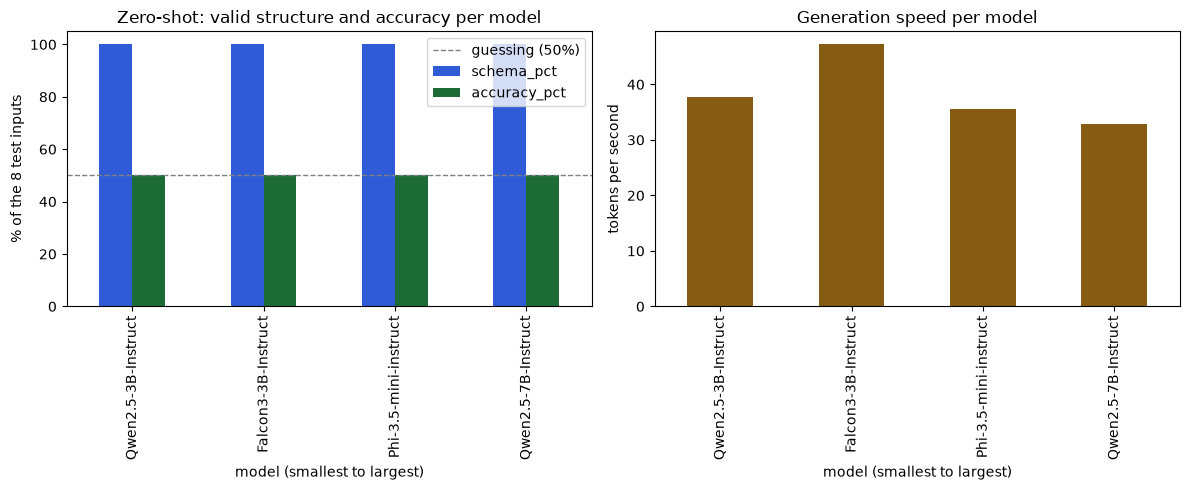

In [10]:
import matplotlib.pyplot as plt

plot = by_model.set_index("model").reindex(by_model.sort_values("params_b")["model"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot[["schema_pct", "accuracy_pct"]].plot.bar(ax=axes[0], color=["#2f5bd7", "#1d6b36"])
axes[0].set_title("Zero-shot: valid structure and accuracy per model")
axes[0].set_ylabel("% of the 8 test inputs")
axes[0].axhline(50, color="grey", linestyle="--", linewidth=1, label="guessing (50%)")
axes[0].legend()
axes[0].set_xlabel("model (smallest to largest)")
plot["tokens_per_s"].plot.bar(ax=axes[1], color="#855c11")
axes[1].set_title("Generation speed per model")
axes[1].set_ylabel("tokens per second")
axes[1].set_xlabel("model (smallest to largest)")
plt.tight_layout()
plt.savefig(f"{RESULTS}/matrix_chart.png", dpi=120)
plt.show()

## 8. Route A: zero-, one-, few- and many-shot prompting

Same 4 methods (0, 1, 3 and 12 worked examples), same 8 inputs, same scoring. The main
benchmark ran this on its top 3 models; here all 4 models are run, since there are only 4.

In [11]:
SHOT_COUNTS = {"zero-shot": 0, "one-shot": 1, "few-shot": 3, "many-shot": 12}
ROUTE_CSV = f"{RESULTS}/prompting_results.csv"
route_rows = load_saved(ROUTE_CSV)
done = {(row["model_id"], row["method"]) for row in route_rows}

route_models = by_model.sort_values("score", ascending=False)[["category", "model_id"]].values.tolist()
print("Route A models:", [m for _, m in route_models])

for category, model_id in route_models:
    todo = [(m, n) for m, n in SHOT_COUNTS.items() if (model_id, m) not in done]
    if not todo:
        continue
    download(model_id)
    for method, n_shots in todo:
        print(f"{model_id} - {method}", flush=True)
        try:
            route_rows += run(model_id, category, n_shots, method)
        except Exception as error:
            print("   failed:", type(error).__name__, error)
        pd.DataFrame(route_rows).to_csv(ROUTE_CSV, index=False)
    if DELETE_AFTER_TEST:
        delete_from_cache(model_id)

route = pd.DataFrame(route_rows)
route.to_csv(ROUTE_CSV, index=False)
print("Saved", ROUTE_CSV, "with", len(route), "rows")

Route A models: ['tiiuae/Falcon3-3B-Instruct', 'Qwen/Qwen2.5-3B-Instruct', 'microsoft/Phi-3.5-mini-instruct', 'Qwen/Qwen2.5-7B-Instruct']


Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Fetching 8 files: 100%|██████████| 8/8 [00:00<00:00, 2666.01it/s]

tiiuae/Falcon3-3B-Instruct - zero-shot


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

Loading weights:  92%|█████████▏| 312/339 [00:05<00:00, 53.20it/s]

Loading weights:  95%|█████████▌| 323/339 [00:05<00:00, 56.78it/s]

Loading weights:  97%|█████████▋| 330/339 [00:06<00:00, 59.00it/s]

Loading weights: 100%|██████████| 339/339 [00:06<00:00, 55.81it/s]

Saved results_3b_plus/prompting_results.csv with 128 rows


In [12]:
by_method = summarise(route, ["model", "method"]).drop(columns="score")
by_method["prompt_tokens"] = route.groupby(["model", "method"], sort=False)["prompt_tokens"].mean().round(0)
by_method

json_pct  schema_pct  accuracy_pct  \
model                 method                                          
Falcon3-3B-Instruct   zero-shot     100.0       100.0          50.0   
                      one-shot      100.0       100.0          50.0   
                      few-shot      100.0       100.0          62.0   
                      many-shot     100.0       100.0          75.0   
Qwen2.5-3B-Instruct   zero-shot     100.0       100.0          50.0   
                      one-shot      100.0       100.0          62.0   
                      few-shot      100.0       100.0          75.0   
                      many-shot     100.0       100.0          88.0   
Phi-3.5-mini-instruct zero-shot     100.0       100.0          50.0   
                      one-shot      100.0       100.0          50.0   
                      few-shot      100.0       100.0          50.0   
                      many-shot     100.0       100.0          88.0   
Qwen2.5-7B-Instruct   zero-shot     100.0       100.0          50.0   
                      one-shot      100.0       100.0          50.0   
                      few-shot      100.0       100.0          62.0   
                      many-shot     100.0       100.0         100.0   

                                 sec_per_answer  tokens_per_s  peak_mem_gb  \
model                 method                                                 
Falcon3-3B-Instruct   zero-shot            1.22          47.4         6.60   
                      one-shot             1.45          45.9         6.62   
                      few-shot             1.37          42.9         6.67   
                      many-shot            1.70          32.7         6.87   
Qwen2.5-3B-Instruct   zero-shot            1.90          39.3         6.31   
                      one-shot             1.36          39.2         6.33   
                      few-shot             1.40          37.4         6.36   
                      many-shot            1.57          33.3         6.48   
Phi-3.5-mini-instruct zero-shot            2.20          35.6         7.88   
                      one-shot             1.95          35.1         7.92   
                      few-shot             3.68          33.7         8.06   
                      many-shot            3.89          28.0         8.61   
Qwen2.5-7B-Instruct   zero-shot            1.60          32.9        15.39   
                      one-shot             1.59          31.9        15.41   
                      few-shot             1.71          30.4        15.46   
                      many-shot            2.06          24.9        15.67   

                                 prompt_tokens  
model                 method                    
Falcon3-3B-Instruct   zero-shot          191.0  
                      one-shot           322.0  
                      few-shot           586.0  
                      many-shot         1763.0  
Qwen2.5-3B-Instruct   zero-shot          188.0  
                      one-shot           306.0  
                      few-shot           540.0  
                      many-shot         1602.0  
Phi-3.5-mini-instruct zero-shot          197.0  
                      one-shot           321.0  
                      few-shot           586.0  
                      many-shot         1755.0  
Qwen2.5-7B-Instruct   zero-shot          188.0  
                      one-shot           306.0  
                      few-shot           540.0  
                      many-shot         1602.0

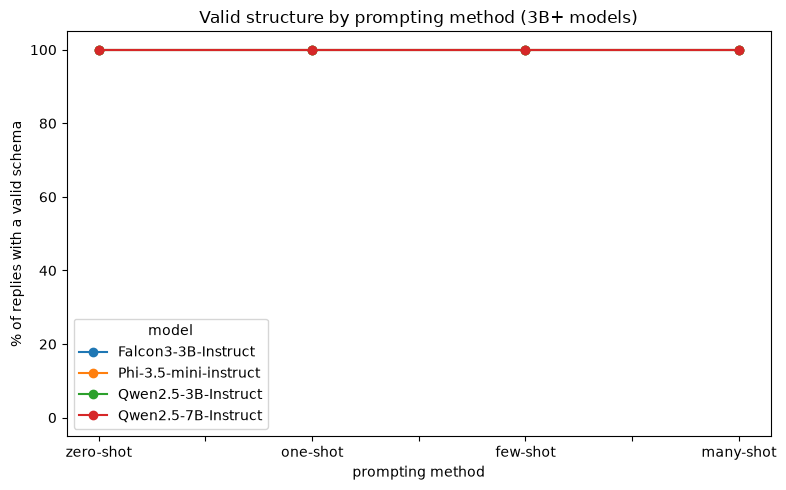

,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb
method,,,,,,
many-shot,100.0,100.0,88.0,2.31,29.7,15.67
few-shot,100.0,100.0,62.0,2.04,36.1,15.46
one-shot,100.0,100.0,53.0,1.59,38.0,15.41
zero-shot,100.0,100.0,50.0,1.73,38.8,15.39


In [13]:
methods = list(SHOT_COUNTS)
pivot = (route.groupby(["method", "model"])["schema_ok"].mean().unstack() * 100).reindex(methods)
ax = pivot.plot(marker="o", figsize=(8, 5))
ax.set_title("Valid structure by prompting method (3B+ models)")
ax.set_ylabel("% of replies with a valid schema")
ax.set_xlabel("prompting method")
ax.set_ylim(-5, 105)
plt.tight_layout()
plt.savefig(f"{RESULTS}/prompting_chart.png", dpi=120)
plt.show()

method_rank = summarise(route, ["method"]).drop(columns="score").sort_values(
    ["schema_pct", "accuracy_pct"], ascending=False)
method_rank

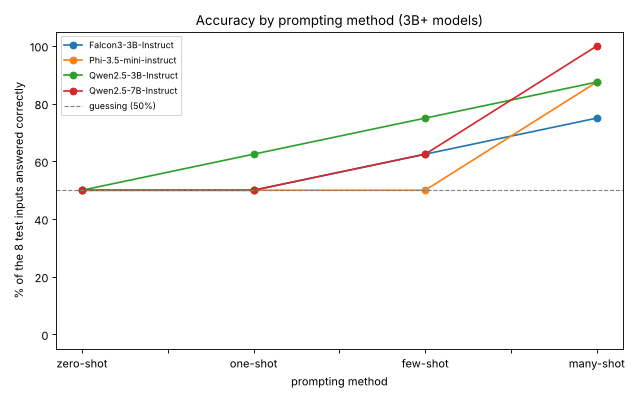

In [ ]:
# Every reply above was valid JSON, so structure cannot separate the methods.
# Accuracy can: this is the chart that answers "which prompting method works".
acc_pivot = (route.groupby(["method", "model"])["correct"].mean().unstack() * 100).reindex(methods)
ax = acc_pivot.plot(marker="o", figsize=(8, 5))
ax.axhline(50, color="grey", linestyle="--", linewidth=1, label="guessing (50%)")
ax.set_title("Accuracy by prompting method (3B+ models)")
ax.set_ylabel("% of the 8 test inputs answered correctly")
ax.set_xlabel("prompting method")
ax.set_ylim(-5, 105)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{RESULTS}/prompting_accuracy_chart.png", dpi=120)
plt.show()

## 9. Size comparison with the light models

This reads the main benchmark's saved results (`results_light/`, read only) and puts all 19
models on one chart: zero-shot accuracy and valid structure against parameter count. It also
compares the few-shot prompt, which the Django app uses, for the best light model
(SmolLM2-1.7B) against these larger models.

In [14]:
light_matrix = pd.read_csv("results_light/matrix_results.csv")
light_route = pd.read_csv("results_light/prompting_results.csv")
light_matrix["source"] = "light (under 2B)"
matrix["source"] = "3B+"

both = pd.concat([light_matrix, matrix], ignore_index=True)
size_table = (both.groupby(["source", "model", "params_b"])
              .agg(schema_pct=("schema_ok", "mean"), accuracy_pct=("correct", "mean"),
                   sec_per_answer=("seconds", "mean"), peak_mem_gb=("peak_mem_gb", "max"))
              .reset_index().sort_values("params_b"))
size_table[["schema_pct", "accuracy_pct"]] = (size_table[["schema_pct", "accuracy_pct"]] * 100).round(0)
size_table["sec_per_answer"] = size_table["sec_per_answer"].round(2)
size_table.to_csv(f"{RESULTS}/size_comparison.csv", index=False)
size_table

,source,model,params_b,schema_pct,accuracy_pct,sec_per_answer,peak_mem_gb
12,light (under 2B),SmolLM2-135M-Instruct,0.13,0.0,0.0,7.56,0.29
10,light (under 2B),SmolLM-360M-Instruct,0.36,12.0,12.0,6.51,0.75
13,light (under 2B),SmolLM2-360M-Instruct,0.36,0.0,0.0,1.40,0.76
7,light (under 2B),Qwen2-0.5B-Instruct,0.49,38.0,12.0,2.67,1.01
8,light (under 2B),Qwen2.5-0.5B-Instruct,0.49,100.0,50.0,2.21,1.02
17,light (under 2B),h2o-danube3-500m-chat,0.51,0.0,0.0,3.52,1.06
14,light (under 2B),TinyLlama-1.1B-Chat-v1.0,1.10,100.0,50.0,4.61,2.24
15,light (under 2B),granite-3.1-1b-a400m-instruct,1.33,12.0,0.0,3.86,2.72
5,light (under 2B),OLMo-2-0425-1B-Instruct,1.48,100.0,50.0,1.90,3.03
9,light (under 2B),Qwen2.5-1.5B-Instruct,1.54,100.0,50.0,3.24,3.12


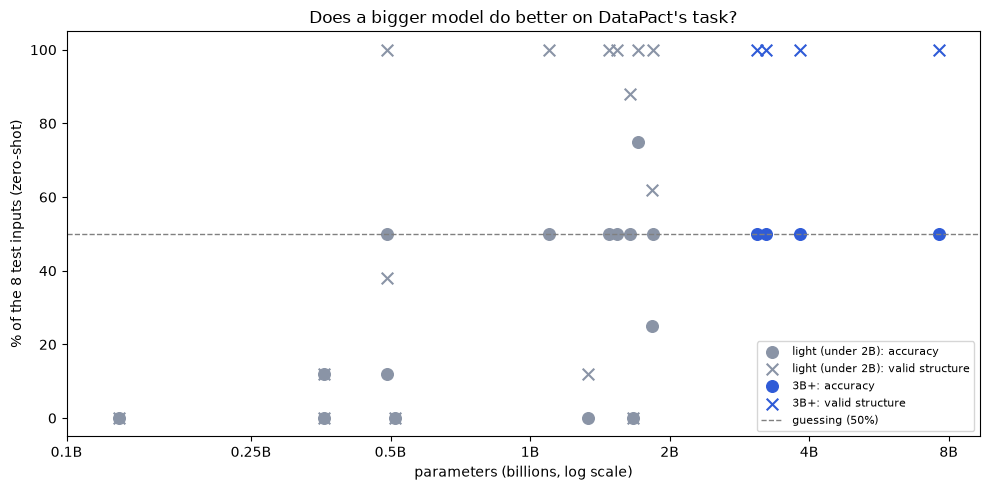

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
for source, color in [("light (under 2B)", "#8a94a6"), ("3B+", "#2f5bd7")]:
    part = size_table[size_table["source"] == source]
    ax.scatter(part["params_b"], part["accuracy_pct"], s=70, color=color, label=f"{source}: accuracy")
    ax.scatter(part["params_b"], part["schema_pct"], s=70, color=color, marker="x",
               label=f"{source}: valid structure")
ax.axhline(50, color="grey", linestyle="--", linewidth=1, label="guessing (50%)")
ax.set_xscale("log")
ticks = [0.1, 0.25, 0.5, 1, 2, 4, 8]
ax.set_xticks(ticks)
ax.set_xticklabels([f"{t:g}B" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("parameters (billions, log scale)")
ax.set_ylabel("% of the 8 test inputs (zero-shot)")
ax.set_title("Does a bigger model do better on DataPact's task?")
ax.set_ylim(-5, 105)
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(f"{RESULTS}/size_comparison_chart.png", dpi=120)
plt.show()

In [16]:
few_shot = pd.concat([
    light_route[(light_route["model"] == "SmolLM2-1.7B-Instruct") & (light_route["method"] == "few-shot")],
    route[route["method"] == "few-shot"],
])
few_shot_table = summarise(few_shot, ["model"]).drop(columns="score")
few_shot_table.insert(0, "params_b", few_shot.groupby("model", sort=False)["model_id"].first().map(
    lambda m: SIZE.get(m, 1.71)))
few_shot_table.to_csv(f"{RESULTS}/few_shot_comparison.csv")
few_shot_table

,params_b,json_pct,schema_pct,accuracy_pct,sec_per_answer,tokens_per_s,peak_mem_gb
model,,,,,,,
SmolLM2-1.7B-Instruct,1.71,100.0,100.0,100.0,1.53,35.4,3.59
Falcon3-3B-Instruct,3.23,100.0,100.0,62.0,1.37,42.9,6.67
Qwen2.5-3B-Instruct,3.09,100.0,100.0,75.0,1.40,37.4,6.36
Phi-3.5-mini-instruct,3.82,100.0,100.0,50.0,3.68,33.7,8.06
Qwen2.5-7B-Instruct,7.62,100.0,100.0,62.0,1.71,30.4,15.46


In [17]:
# A few raw replies, to show what "valid" and "invalid" look like for the bigger models.
sample = matrix.sort_values(["schema_ok", "params_b"]).groupby("schema_ok").head(3)
for _, row in sample.iterrows():
    print(f"--- {row['model']} on {row['case']} (schema ok: {row['schema_ok']}) ---")
    print(str(row["output"])[:400], "\n")

--- Qwen2.5-3B-Instruct on T1 (schema ok: True) ---
{
  "explanation": "The dataset contains invalid values such as 31 and -2 in the 'credit_hours' column, which exceed the allowed range of 0 to 24, indicating that the incoming data is wrong.",
  "likely_cause": "DATA_ISSUE",
  "suggested_action": "Review and correct the data to ensure it falls within the specified range."
} 

--- Qwen2.5-3B-Instruct on T2 (schema ok: True) ---
{
  "explanation": "The incoming data contains invalid status values that do not match the allowed values defined in the rule, indicating a DATA_ISSUE.",
  "likely_cause": "DATA_ISSUE",
  "suggested_action": "Review and correct the status values to ensure they align with 'ENROLLED', 'DROPPED', or 'WITHDRAWN'."
} 

--- Qwen2.5-3B-Instruct on T3 (schema ok: True) ---
{
  "explanation": "The dataset contains invalid student IDs that do not match the expected format, indicating a DATA_ISSUE.",
  "likely_cause": "DATA_ISSUE",
  "suggested_action": "Review and correct

## 10. Findings

*Written after the full run (AMD Radeon RX 7900 XTX, 24 GB, PyTorch 2.9.1 + ROCm 7.2.1 on Windows, 19 Oct 2026), from the tables above. With 8 test inputs, one answer moves a score by 12.5 points.*

**1. Bigger models fix the structure, not the reasoning.** All 4 models (3.1B to 7.6B) returned valid JSON on every one of the 128 + 32 replies, at every prompting method. That beats the light models, where only 6 of 15 managed 100%. But at zero-shot, all 4 answered `DATA_ISSUE` for all 8 inputs, so each scored exactly 50%, the same as guessing. Even the 7B model treated every unknown value as bad data unless it was shown examples.

**2. Examples matter more than size.** Averaged over the 4 models:

| Method | Valid structure | Accuracy | Prompt tokens | Seconds per answer |
|---|---|---|---|---|
| zero-shot | 100% | 50% | ~190 | 1.73 |
| one-shot | 100% | 53% | ~315 | 1.59 |
| few-shot (3 examples) | 100% | 62% | ~565 | 2.04 |
| many-shot (12 examples) | 100% | 88% | ~1,680 | 2.31 |

With 12 examples, Qwen2.5-7B got **8/8**, and Qwen2.5-3B and Phi-3.5-mini got 7/8. Qwen2.5-7B was the only model to get T2 right (the new `AUDIT` status, which has only 4 failed rows), so its extra size shows up only on the hardest case, and only once it has many examples.

**3. The few-shot prompt the app uses works better on the small model.** On the same 3-example prompt, SmolLM2-1.7B (main benchmark) scored 100%. The 3B+ models scored 50% to 75%, and Qwen2.5-7B scored 62.5%. The 7B model needs the 12-example prompt (3x the tokens) to match what SmolLM2 does with 3.

**4. Size vs cost.** Peak GPU memory (the longer many-shot prompts use the most): 6.3 to 6.9 GB for the 3B models, 7.9 to 8.6 GB for Phi-3.5-mini, and **15.4 to 15.7 GB for Qwen2.5-7B**, against 3.6 GB for SmolLM2-1.7B. The 7B model needs a 16 GB+ GPU (more than the 15 GB on Colab's free T4), while SmolLM2 runs on a small GPU or about 7 GB of CPU RAM. Speed on this GPU was similar for all of them (1.2 to 3.9 s per answer), so memory, not speed, is the real cost of going bigger.

**Conclusion for DataPact.** A massive model was not significantly better for this task. The sweet spot stays at **SmolLM2-1.7B with the few-shot prompt**. A 7B model only pays off if we also switch to a 12-example prompt, and then it needs about 4x the memory for a one-answer gain on the hardest case. For a hosted deployment where neither fits, the external API (Groq) is the better path than renting a GPU for a 7B model.
